# Archivos económicos del Perú: ¿se pueden buscar?

**Notebook 02 — Evaluación: CER/WER, LLM y comparativa de modelos**

## 1. Muestra de evaluacion (fijada antes de ver cualquier metrica)

La muestra se definio el 25-10-2026, **antes de calcular CER o WER** y antes de leer el texto
del OCR o del ASR. La referencia la transcribe a mano la estudiante en
`datos/referencias_documentos.md` y `datos/referencias_audio.md`. Esos archivos no muestran
la salida de ningun modelo, para no sesgar la transcripcion.

### Documentos: 10, elegidos a mano por tipo

Reparto **4 impresos, 3 fotos y 3 manuscritos**, para poder medir el error por tipo.
Criterio: se prefieren paginas de **texto corrido** antes que tablas densas de cifras,
porque en una tabla el orden de lectura es ambiguo y el CER mediria el orden, no la lectura.

| Tipo | Documento | Por que entra |
|---|---|---|
| impreso | Carta a Gamarra p023 (Notas) | **obligatoria**: confianza media 0.98 en la pagina mas manchada. Se quiere comprobar si el modelo esta seguro de una lectura erronea |
| impreso | Carta a Gamarra p003 | texto corrido de 1832, tipografia antigua |
| impreso | Memoria BCRP 1922 p002 | texto corrido con montos en libras peruanas |
| impreso | Memoria BCRP 1923 p003 | texto corrido con montos, escaneo gris |
| foto | Regulacion, conceptos | texto corrido fotografiado |
| foto | Sintesis del Reporte de Inflacion, marzo 2019 | texto en columnas con porcentajes |
| foto | Boleta electronica | pocas palabras y muchas cifras: sirve para medir la exactitud de los montos |
| manuscrito | Cuaderno 1 | texto corrido a mano |
| manuscrito | Cuaderno 3 | texto a mano con cifras y porcentajes |
| manuscrito | Hoja de calle (textileria inca) | texto corrido a mano en hoja suelta |

Quedan fuera de la muestra las portadas, el balance de 1922 y el Cuadro N.º 3 de 1923 (tablas
densas), las fotos de tabla o de etiqueta, y los manuscritos dominados por formulas.
Las 4 fotos que se agregaron despues (horario, pizzas, letrero de Av. Sol y afiche de transito)
no entran: la muestra se fijo antes de tenerlas.

### Audio: 10 clips al azar de los 400

- **Semilla: `20261025`** (fecha de la seleccion), con `random.Random(SEMILLA).sample`.
- Se muestrea sobre la lista de clips **ordenada por nombre de archivo**, para que el resultado no
  dependa del orden en que se descargaron.
- Se usa solo el nombre del archivo, el hablante y el sexo. La transcripcion oficial de OpenSLR
  **no se carga**: la referencia la escribe la estudiante escuchando.
- Id de cada clip: `aud_` + nombre del archivo sin extension, la misma regla que usa
  `transcribir_audio.py`. Los 10 ids estan en `datos/transcripciones.csv`.
- El sorteo se hace solo entre los 400 clips de OpenSLR 73. Las 2 grabaciones `espika`
  (conversacion y musica) quedan fuera de esta muestra aleatoria.

In [1]:
import random
from pathlib import Path

import pandas as pd

SEMILLA_AUDIO = 20261025
N_CLIPS = 10

# Documentos: elegidos a mano, por id estable (ver ocr_documentos.py)
MUESTRA_DOCS = [
    "imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023",
    "imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003",
    "imp_Memoria_BCRP_1922_p002",
    "imp_Memoria_BCRP_1923_p003",
    "fot_Foto_regulacion_conceptos",
    "fot_Foto_sintesis_reporte_marzo_2019",
    "fot_Foto_boletas",
    "man_Manuscrito_cuaderno1",
    "man_Manuscrito_cuaderno3",
    "man_Manuscrito_hoja_calle",
]

# solo id, archivo y tipo: el texto del OCR no se mira al elegir
docs = pd.read_csv("datos/documentos.csv", usecols=["id", "archivo", "tipo"])
muestra_docs = docs.set_index("id").loc[MUESTRA_DOCS].reset_index()
muestra_docs["modalidad"] = "documento"
assert muestra_docs["tipo"].value_counts().to_dict() == {"impreso": 4, "foto": 3, "manuscrito": 3}

# Audio: muestra aleatoria con semilla fija, sin cargar la transcripcion oficial
clips = (pd.read_csv("datos/raw/audio/es_peru/clips.csv", usecols=["archivo", "hablante", "sexo"])
         .sort_values("archivo").reset_index(drop=True))
elegidos = sorted(random.Random(SEMILLA_AUDIO).sample(list(clips["archivo"]), N_CLIPS))
muestra_audio = clips[clips["archivo"].isin(elegidos)].copy()
muestra_audio["id"] = "aud_" + muestra_audio["archivo"].map(lambda a: Path(a).stem)
muestra_audio["tipo"] = "audio"
muestra_audio["modalidad"] = "audio"

muestra = pd.concat([muestra_docs, muestra_audio], ignore_index=True)[
    ["id", "modalidad", "tipo", "archivo", "hablante", "sexo"]]
muestra.to_csv("datos/muestra_evaluacion.csv", index=False)
print(f"Semilla de audio: {SEMILLA_AUDIO} · {len(clips)} clips disponibles")
print(muestra_audio["sexo"].value_counts().to_string())
muestra

Semilla de audio: 20261025 · 400 clips disponibles
sexo
hombre    6
mujer     4


,id,modalidad,tipo,archivo,hablante,sexo
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_...,documento,impreso,Manuscrito-31_PE_1352-Carta_escrita_a_Don_Agus...,NaN,NaN
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_...,documento,impreso,Manuscrito-31_PE_1352-Carta_escrita_a_Don_Agus...,NaN,NaN
2,imp_Memoria_BCRP_1922_p002,documento,impreso,Memoria-BCRP-1922_p002.jpg,NaN,NaN
3,imp_Memoria_BCRP_1923_p003,documento,impreso,Memoria-BCRP-1923_p003.jpg,NaN,NaN
4,fot_Foto_regulacion_conceptos,documento,foto,Foto_regulacion_conceptos.jpeg,NaN,NaN
5,fot_Foto_sintesis_reporte_marzo_2019,documento,foto,Foto_sintesis_reporte_marzo_2019.jpeg,NaN,NaN
6,fot_Foto_boletas,documento,foto,Foto_boletas.jpeg,NaN,NaN
7,man_Manuscrito_cuaderno1,documento,manuscrito,Manuscrito_cuaderno1.jpeg,NaN,NaN
8,man_Manuscrito_cuaderno3,documento,manuscrito,Manuscrito_cuaderno3.jpeg,NaN,NaN
9,man_Manuscrito_hoja_calle,documento,manuscrito,Manuscrito_hoja_calle.jpeg,NaN,NaN


## 2. Referencias humanas -> columna `texto_referencia`

Las transcripciones a mano estan en `datos/referencias_documentos.md` y `datos/referencias_audio.md`.
Cada una va debajo de su encabezado `## id: ...`. Esta celda las lee y las copia a la columna
`texto_referencia` de `documentos.csv` y `transcripciones.csv`, **sin tocar ninguna otra columna**
(se leen y se escriben como texto, para que no cambie el formato de los numeros).

La referencia se copia **tal cual**, con sus marcas entre corchetes. Las marcas se tratan despues,
solo al momento de medir (seccion 3).

In [2]:
import re
import unicodedata
from collections import Counter

import jiwer
import plotly.express as px
import plotly.io as pio
from rapidfuzz import fuzz

# GitHub no muestra los graficos interactivos: si hay kaleido, se guarda tambien una imagen PNG
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width, pio.renderers["png"].height = 900, 520
except ImportError:
    pio.renderers.default = "plotly_mimetype"

COLORES = {"impreso": "#4C78A8", "foto": "#F58518", "manuscrito": "#54A24B"}
pd.set_option("display.max_colwidth", 80)


def leer_referencias(ruta):
    # {id: texto} con el texto que esta entre '**Transcripcion:**' y el comentario '<!-- ... -->'
    md = Path(ruta).read_text(encoding="utf-8")
    refs = {}
    for bloque in re.split(r"^## id: ", md, flags=re.M)[1:]:
        ident, cuerpo = bloque.split("\n", 1)
        texto = cuerpo.split("**Transcripcion:**", 1)[1]
        texto = re.split(r"<!--.*?-->|^---\s*$", texto, flags=re.M | re.S)[0]
        refs[ident.strip()] = texto.strip()
    return refs


def copiar_a_csv(ruta_csv, refs):
    tabla = pd.read_csv(ruta_csv, dtype=str, keep_default_na=False)
    antes = tabla.drop(columns="texto_referencia").copy()
    faltan = set(refs) - set(tabla["id"])
    assert not faltan, f"ids de la referencia que no estan en {ruta_csv}: {faltan}"
    tabla["texto_referencia"] = tabla["id"].map(refs).fillna(tabla["texto_referencia"])
    assert tabla.drop(columns="texto_referencia").equals(antes)   # nada mas cambio
    tabla.to_csv(ruta_csv, index=False, encoding="utf-8")
    return tabla


refs_doc = leer_referencias("datos/referencias_documentos.md")
refs_aud = leer_referencias("datos/referencias_audio.md")
assert set(refs_doc) == set(MUESTRA_DOCS) and set(refs_aud) == set(muestra_audio["id"])
assert all(refs_doc.values()) and all(refs_aud.values()), "hay una referencia vacia"

docs = copiar_a_csv("datos/documentos.csv", refs_doc)
trans = copiar_a_csv("datos/transcripciones.csv", refs_aud)
print(f"documentos.csv:      {(docs['texto_referencia'] != '').sum()} filas con referencia")
print(f"transcripciones.csv: {(trans['texto_referencia'] != '').sum()} filas con referencia")
pd.DataFrame({"id": list(refs_doc) + list(refs_aud),
              "caracteres_referencia": [len(t) for t in list(refs_doc.values()) + list(refs_aud.values())]})

documentos.csv:      10 filas con referencia
transcripciones.csv: 10 filas con referencia


,id,caracteres_referencia
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023,2295
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,2313
2,imp_Memoria_BCRP_1922_p002,2536
3,imp_Memoria_BCRP_1923_p003,2699
4,fot_Foto_regulacion_conceptos,3755
5,fot_Foto_sintesis_reporte_marzo_2019,2340
6,fot_Foto_boletas,666
7,man_Manuscrito_cuaderno1,967
8,man_Manuscrito_cuaderno3,950
9,man_Manuscrito_hoja_calle,467


## 3. Normalizacion y marcas entre corchetes

**Normalizar** es poner los dos textos en la misma forma antes de compararlos, para que el error
mida la *lectura* y no detalles de formato. Se aplica igual a la referencia y al modelo:

1. Minusculas y Unicode NFC (una tilde se guarda siempre igual).
2. **Guiones de fin de linea**: `don- de` -> `donde`. Solo entre dos letras, para no pegar
   rangos como `2019-2020`. Es un corte de linea de la pagina, no un error de lectura.
3. Se quita la puntuacion y los espacios repetidos. **Las tildes se quedan**: `año` y `ano`
   no son lo mismo. (Misma regla que `normalizar()` de `voz.py`, sesion 13 del curso.)

Solo para el **WER**, ademas:

4. Se borran las **marcas de hablante y de tiempo** (`[00:01:56]`, `ENTREVISTADO (Peru):`,
   `SPEAKER_00`, `[HABLANTE 1]`), en los dos lados.
5. Las **cifras escritas con digitos se pasan a palabras** (`10` -> `diez`). La convencion de la
   referencia es escribir lo que se oye ("diez horas"), y Whisper escribe digitos. Sin este paso,
   el WER castigaria un formato, no un error de oido. Se reporta tambien el WER sin este paso.

**Marcas entre corchetes en la referencia.** No son texto de la pagina, asi que no se cuentan.
Se clasifican en tres clases:

| Clase | Ejemplos | Que se hace |
|---|---|---|
| zona omitida | `[grafico no transcrito]`, `[tabla no transcrita]`, `[codigo QR omitido]` | se borra la marca **y se recorta el OCR a la misma zona** (seccion 4) |
| ilegible | `[ilegible]` | se borra la marca; el OCR no se recorta (ver nota) |
| simbolo del texto | `[*]` (llamada de nota en la carta de 1832) | es texto de la pagina: se deja |

Nota sobre `[ilegible]`: la persona si transcribio esa zona, solo que no pudo leer unas palabras.
No hay forma objetiva de saber que tramo del OCR corresponde a esas palabras, asi que lo que el OCR
lea alli cuenta como insercion. Eso sube un poco el CER de esos documentos (es un sesgo
conservador: el error real no puede ser mayor que el medido por esta causa). Las cifras pegadas a
un `[ilegible]` se excluyen del conteo de cifras (seccion 6), porque no hay cifra de referencia.

In [3]:
MARCA = re.compile(r"`?\[([^\]]*[A-Za-zÁÉÍÓÚáéíóúñ][^\]]*)\]`?")   # corchetes con letras dentro
ZONA_OMITIDA = re.compile(r"no transcrit|omitid|grafico|gráfico|tabla|qr", re.I)
HABLANTE = re.compile(r"\[\d{2}:\d{2}:\d{2}(?:[.,]\d+)?\]"                # [00:01:56]
                      r"|^\s*[A-ZÁÉÍÓÚÑ][A-ZÁÉÍÓÚÑ ]+(?:\([^)]*\))?:"     # ENTREVISTADO (Peru):
                      r"|\[?\b(?:SPEAKER|HABLANTE)[ _]?\w*\]?:?", re.M)


def clase_marca(m):
    if "ilegible" in m.lower():
        return "ilegible"
    return "zona omitida" if ZONA_OMITIDA.search(m) else "otra"


def quitar_marcas(texto):
    return MARCA.sub(" ", texto)


def normalizar(texto):
    texto = unicodedata.normalize("NFC", texto.lower())
    texto = re.sub(r"([a-záéíóúüñ])-\s+([a-záéíóúüñ])", r"\1\2", texto)   # guion de fin de linea
    texto = re.sub(r"[^\w\s']", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


UNIDADES = ("cero uno dos tres cuatro cinco seis siete ocho nueve diez once doce trece catorce quince "
            "dieciseis diecisiete dieciocho diecinueve veinte veintiuno veintidos veintitres "
            "veinticuatro veinticinco veintiseis veintisiete veintiocho veintinueve").split()
DECENAS = "_ _ _ treinta cuarenta cincuenta sesenta setenta ochenta noventa".split()
CENTENAS = ("_ ciento doscientos trescientos cuatrocientos quinientos seiscientos setecientos "
            "ochocientos novecientos").split()
UNIDADES[16], UNIDADES[22], UNIDADES[23], UNIDADES[26] = "dieciséis", "veintidós", "veintitrés", "veintiséis"


def en_palabras(n):
    # Entero (0 a 999 999) en palabras, como se dice en espanol
    if n < 30:
        return UNIDADES[n]
    if n < 100:
        d, u = divmod(n, 10)
        return DECENAS[d] + (f" y {UNIDADES[u]}" if u else "")
    if n < 1000:
        c, r = divmod(n, 100)
        return "cien" if n == 100 else CENTENAS[c] + (f" {en_palabras(r)}" if r else "")
    m, r = divmod(n, 1000)
    return ("mil" if m == 1 else f"{en_palabras(m)} mil") + (f" {en_palabras(r)}" if r else "")


def normalizar_habla(texto, cifras_a_palabras=True):
    texto = HABLANTE.sub(" ", quitar_marcas(texto))
    if cifras_a_palabras:
        texto = re.sub(r"\d{1,6}", lambda m: f" {en_palabras(int(m.group()))} ", texto)
    return normalizar(texto)


# Inventario de marcas en las referencias
marcas = pd.DataFrame([{"id": i, "marca": m, "clase": clase_marca(m)}
                       for i, t in {**refs_doc, **refs_aud}.items() for m in MARCA.findall(t)])
otros_corchetes = {i: re.findall(r"\[[^\]A-Za-z]*\]", t) for i, t in refs_doc.items()}
print("Corchetes sin letras (se dejan como texto):", {k: v for k, v in otros_corchetes.items() if v})
print("Marcas de hablante en la referencia de audio:",
      sum(bool(HABLANTE.search(t)) for t in refs_aud.values()),
      "| en la salida del ASR de la muestra:",
      sum(bool(HABLANTE.search(t)) for t in trans.set_index("id").loc[list(refs_aud), "texto_asr"]))
marcas.groupby(["id", "marca", "clase"]).size().rename("veces").reset_index()

Corchetes sin letras (se dejan como texto): {'imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023': ['[*]']}
Marcas de hablante en la referencia de audio: 0 | en la salida del ASR de la muestra: 0


,id,marca,clase,veces
0,fot_Foto_boletas,código QR omitido,zona omitida,1
1,fot_Foto_boletas,ilegible,ilegible,3
2,fot_Foto_sintesis_reporte_marzo_2019,gráfico no transcrito,zona omitida,2
3,fot_Foto_sintesis_reporte_marzo_2019,tabla no transcrita,zona omitida,1
4,imp_Memoria_BCRP_1922_p002,ilegible,ilegible,1
5,man_Manuscrito_hoja_calle,ilegible,ilegible,1


## 4. Recorte del OCR en las zonas que la referencia omite

Dos documentos tienen marcas de **zona omitida**:

- **Sintesis del Reporte de Inflacion**: la referencia transcribe los *titulos* de los dos graficos y
  del cuadro, pero no su contenido (ejes, barras, cifras del cuadro). PaddleOCR si lee esas zonas:
  si se dejaran, cada numero del eje contaria como un error de insercion que la persona decidio no
  transcribir, y el CER mediria esa decision, no la calidad del OCR.
- **Boleta**: `[codigo QR omitido]`.

**Criterio.** Se recorta por **posicion en la imagen**, no por contenido: se definen a mano, mirando
la foto, los rectangulos que ocupa el *cuerpo* de cada grafico, cuadro o QR (sin sus titulos, que si
estan en la referencia), y se quita del OCR **toda linea cuyo centro cae dentro**, lea bien o mal.
Asi el recorte no puede favorecer al modelo: no se eligen lineas mirando si coinciden con la
referencia. Las zonas se fijaron antes de calcular el CER.

**De donde salen las posiciones.** `datos/ocr_lineas.csv` guarda el texto y la confianza de cada
linea, pero no su caja. Por eso se volvio a correr **la misma linea base** (PP-OCRv6, mismos
parametros que `ocr_documentos.py`) solo sobre estas 2 imagenes y se guardaron las cajas en
`datos/ocr_cajas_muestra.csv`. La celda lo comprueba: desde que el OCR del corpus se re-ejecuto sobre las imagenes actuales
(25-10-2026, al sumar las 4 fotos nuevas), la re-ejecucion coincide linea por linea con
`ocr_lineas.csv` en las dos imagenes.
Para el Reporte recortado y para el analisis de orden se usan las lineas de la re-ejecucion.

In [4]:
RUTA_CAJAS = Path("datos/ocr_cajas_muestra.csv")
IMAGENES_CAJAS = {"fot_Foto_sintesis_reporte_marzo_2019": "datos/raw/documentos/fotos/Foto_sintesis_reporte_marzo_2019.jpeg",
                  "fot_Foto_boletas": "datos/raw/documentos/fotos/Foto_boletas.jpeg"}

if not RUTA_CAJAS.exists():          # solo si falta el archivo: vuelve a correr la linea base
    from paddleocr import PaddleOCR
    ocr = PaddleOCR(engine="transformers", use_doc_orientation_classify=True,
                    use_doc_unwarping=False, use_textline_orientation=False)
    filas = []
    for ident, ruta in IMAGENES_CAJAS.items():
        r = ocr.predict(ruta)[0]
        for n, (t, s, b) in enumerate(zip(r["rec_texts"], r["rec_scores"], r["rec_boxes"]), start=1):
            filas.append(dict(id=ident, linea=n, texto=t, confianza=round(float(s), 4),
                              x0=int(b[0]), y0=int(b[1]), x1=int(b[2]), y1=int(b[3])))
    pd.DataFrame(filas).to_csv(RUTA_CAJAS, index=False)

cajas = pd.read_csv(RUTA_CAJAS, dtype={"texto": str}, keep_default_na=False)
cajas["xc"], cajas["yc"] = (cajas.x0 + cajas.x1) / 2, (cajas.y0 + cajas.y1) / 2
lineas = pd.read_csv("datos/ocr_lineas.csv", dtype={"texto": str}, keep_default_na=False)

# Zonas omitidas en la referencia: (x0, y0, x1, y1) en pixeles de la imagen (1125 x 1500),
# medidas a mano sobre la foto. Solo el cuerpo del grafico/cuadro, sin el titulo.
ZONAS = {
    "fot_Foto_sintesis_reporte_marzo_2019": {
        "grafico Economia mundial (ejes, barras, fuente)": (600, 545, 1125, 780),
        "cuadro Terminos de intercambio (filas y cifras)":  (600, 860, 1125, 1210),
        "grafico Cuenta corriente (barras, ejes, leyenda)": (600, 1280, 1125, 1500),
    },
    "fot_Foto_boletas": {"codigo QR": (400, 1290, 600, 1460)},
}


def en_zona(fila, zonas):
    return next((n for n, (x0, y0, x1, y1) in zonas.items()
                 if x0 <= fila.xc <= x1 and y0 <= fila.yc <= y1), "")


cajas["zona_omitida"] = [en_zona(f, ZONAS.get(f.id, {})) for f in cajas.itertuples()]

for ident in IMAGENES_CAJAS:
    a = lineas.loc[lineas.id == ident, "texto"].tolist()
    b = cajas.loc[cajas.id == ident, "texto"].tolist()
    cambian = cajas[(cajas.id == ident) & ~cajas.texto.isin(a)]
    print(f"{ident}: {len(a)} lineas en ocr_lineas.csv, {len(b)} en la re-ejecucion; "
          f"lineas distintas: {len(cambian)}, de ellas fuera de zonas recortadas: "
          f"{list(cambian.loc[cambian.zona_omitida == '', 'texto'])}")

TEXTO_OCR = docs.set_index("id")["texto_ocr"].to_dict()        # linea base, tal como esta en el CSV
TEXTO_OCR_RECORTADO = dict(TEXTO_OCR)
for ident in IMAGENES_CAJAS:
    quedan = cajas[(cajas.id == ident) & (cajas.zona_omitida == "")]
    TEXTO_OCR_RECORTADO[ident] = " ".join(t.strip() for t in quedan.texto if t.strip())

(cajas[cajas.zona_omitida != ""].groupby(["id", "zona_omitida"])
 .agg(lineas_quitadas=("texto", "size"), caracteres=("texto", lambda s: s.str.len().sum()),
      ejemplo=("texto", lambda s: " | ".join(s.head(6))))
 .reset_index())

fot_Foto_sintesis_reporte_marzo_2019: 174 lineas en ocr_lineas.csv, 174 en la re-ejecucion; lineas distintas: 0, de ellas fuera de zonas recortadas: []
fot_Foto_boletas: 41 lineas en ocr_lineas.csv, 41 en la re-ejecucion; lineas distintas: 0, de ellas fuera de zonas recortadas: []


,id,zona_omitida,lineas_quitadas,caracteres,ejemplo
0,fot_Foto_sintesis_reporte_marzo_2019,cuadro Terminos de intercambio (filas y cifras),83,567,2017 | 2018 | 2019* | 2020- | Dic. 18 | RI Mar 19
1,fot_Foto_sintesis_reporte_marzo_2019,"grafico Cuenta corriente (barras, ejes, leyenda)",23,161,10.8 | 9.8 | 7.8 | 7.0 | 6.6 | -17
2,fot_Foto_sintesis_reporte_marzo_2019,"grafico Economia mundial (ejes, barras, fuente)",17,109,"5.0 | 4.0 | 3,0 | 2,0 | 1,0 | 0,0"


## 5. CER de los 10 documentos (linea base PaddleOCR PP-OCRv6)

**CER** (*character error rate*): cuantas letras hay que cambiar, borrar o agregar al texto del OCR
para llegar a la referencia, dividido por el numero de letras de la referencia. 0 = perfecto;
puede pasar de 1 si el OCR inventa mucho texto.

Se reportan dos columnas: `cer_sin_recorte` (todo el texto del OCR) y `cer` (con el recorte de la
seccion 4). **La cifra oficial es `cer`.** Por tipo se dan dos promedios:

- **promedio simple**: cada documento pesa igual;
- **agregado**: suma de errores / suma de caracteres de todos los documentos del tipo (pesa mas
  el documento mas largo). Es el que calcula `jiwer.cer` sobre la lista.

In [5]:
ORDEN_TIPOS = ["impreso", "foto", "manuscrito"]
tipo_de = docs.set_index("id")["tipo"]

ev_doc = pd.DataFrame({"id": MUESTRA_DOCS})
ev_doc["tipo"] = ev_doc["id"].map(tipo_de)
ev_doc["ref"] = ev_doc["id"].map(lambda i: normalizar(quitar_marcas(refs_doc[i])))
ev_doc["ocr_completo"] = ev_doc["id"].map(lambda i: normalizar(TEXTO_OCR[i]))
ev_doc["ocr"] = ev_doc["id"].map(lambda i: normalizar(TEXTO_OCR_RECORTADO[i]))
ev_doc["caracteres_ref"] = ev_doc["ref"].str.len()
ev_doc["cer_sin_recorte"] = [jiwer.cer(r, h or "∅") for r, h in zip(ev_doc.ref, ev_doc.ocr_completo)]
ev_doc["cer"] = [jiwer.cer(r, h or "∅") for r, h in zip(ev_doc.ref, ev_doc.ocr)]
conf = lineas.groupby("id")["confianza"].mean()
ev_doc["confianza_media_ocr"] = ev_doc["id"].map(conf).round(3)

tabla_cer = ev_doc[["id", "tipo", "caracteres_ref", "confianza_media_ocr", "cer_sin_recorte", "cer"]].round(3)
tabla_cer

,id,tipo,caracteres_ref,confianza_media_ocr,cer_sin_recorte,cer
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023,impreso,2192,0.977,0.040,0.040
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,impreso,2267,0.555,0.904,0.904
2,imp_Memoria_BCRP_1922_p002,impreso,2476,0.986,0.022,0.022
3,imp_Memoria_BCRP_1923_p003,impreso,2655,0.992,0.009,0.009
4,fot_Foto_regulacion_conceptos,foto,3678,0.973,0.041,0.041
5,fot_Foto_sintesis_reporte_marzo_2019,foto,2233,0.934,0.759,0.459
6,fot_Foto_boletas,foto,578,0.959,0.114,0.114
7,man_Manuscrito_cuaderno1,manuscrito,942,0.943,0.101,0.101
8,man_Manuscrito_cuaderno3,manuscrito,929,0.903,0.115,0.115
9,man_Manuscrito_hoja_calle,manuscrito,449,0.886,0.241,0.241


In [6]:
por_tipo = (ev_doc.groupby("tipo")
            .apply(lambda g: pd.Series({
                "documentos": len(g),
                "cer_promedio_simple": g["cer"].mean(),
                "cer_agregado": jiwer.cer(list(g.ref), [h or "∅" for h in g.ocr]),
                "cer_min": g["cer"].min(), "cer_max": g["cer"].max()}), include_groups=False)
            .loc[ORDEN_TIPOS])
total = pd.DataFrame({"documentos": len(ev_doc), "cer_promedio_simple": ev_doc["cer"].mean(),
                      "cer_agregado": jiwer.cer(list(ev_doc.ref), [h or "∅" for h in ev_doc.ocr]),
                      "cer_min": ev_doc["cer"].min(), "cer_max": ev_doc["cer"].max()}, index=["TOTAL"])
CER_POR_TIPO = pd.concat([por_tipo, total]).round(3)

# El promedio de los impresos lo domina una sola pagina: se muestra tambien sin ella
P003 = "imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003"
sin = ev_doc[ev_doc.id != P003]
print(f"CER agregado de impresos sin la p003: "
      f"{jiwer.cer(list(sin[sin.tipo == 'impreso'].ref), list(sin[sin.tipo == 'impreso'].ocr)):.3f}"
      f"  | total sin la p003: {jiwer.cer(list(sin.ref), list(sin.ocr)):.3f}")
CER_POR_TIPO

CER agregado de impresos sin la p003: 0.023  | total sin la p003: 0.106


,documentos,cer_promedio_simple,cer_agregado,cer_min,cer_max
impreso,4.0,0.244,0.231,0.009,0.904
foto,3.0,0.205,0.191,0.041,0.459
manuscrito,3.0,0.152,0.134,0.101,0.241
TOTAL,10.0,0.205,0.205,0.009,0.904


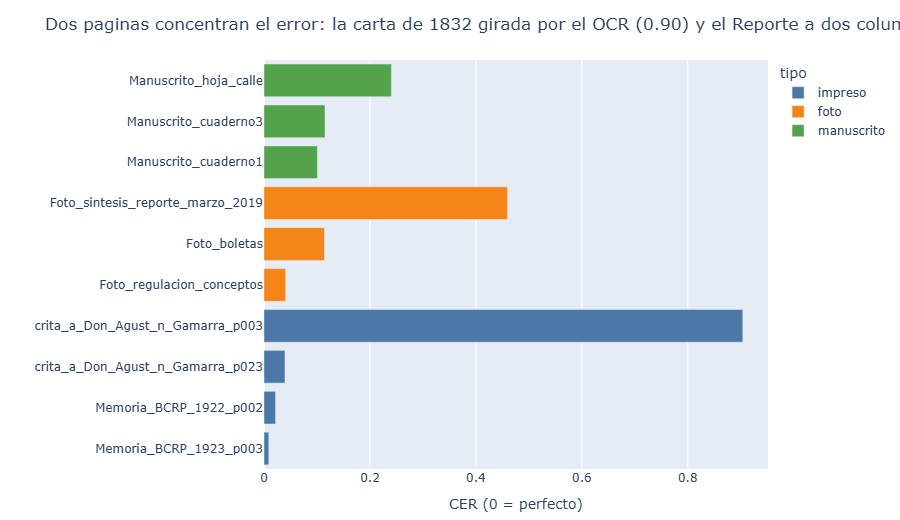

In [7]:
REPORTE = "fot_Foto_sintesis_reporte_marzo_2019"
cer_de = ev_doc.set_index("id")["cer"]
g = ev_doc.assign(documento=ev_doc["id"].str.replace(r"^(imp|fot|man)_", "", regex=True).str[-32:])
fig = px.bar(g.sort_values("cer"), x="cer", y="documento", color="tipo", orientation="h",
             color_discrete_map=COLORES, category_orders={"tipo": ORDEN_TIPOS},
             labels={"cer": "CER (0 = perfecto)", "documento": ""},
             title=(f"Dos paginas concentran el error: la carta de 1832 girada por el OCR "
                    f"({cer_de[P003]:.2f}) y el Reporte a dos columnas ({cer_de[REPORTE]:.2f})"))
fig.update_layout(height=480, margin=dict(l=10, r=10, t=60, b=10))
fig.show()

### 5.1 Lo que el CER no ve: errores de estructura

El CER cuenta letras, no **estructura**. Dos errores de estructura dejan el texto dificil de usar y
el CER no los mide bien:

- **Orden de lectura** (seccion 8). En el Reporte a dos columnas el CER marca 0,46, pero el **98 % de
  las palabras esta bien leido**: el error es el orden. El CER no distingue "leyo mal" de "leyo bien
  pero en otro orden": las dos cosas dan el mismo numero.
- **Puntos entre frases.** La normalizacion de la seccion 3 quita la puntuacion antes de comparar,
  asi que un punto perdido cuesta **cero** en el CER. Ejemplo en la Memoria de 1923 (CER 0,009):
  la referencia dice `...utilizadas por los Bancos Asociados.` y empieza una frase nueva; el OCR
  entrega `...utilizadas por los Ban- cos Asociados Las operaciones de descuento...`, sin el punto.
  Para el CER es la misma frase. Para quien quiera separar el texto en oraciones (un buscador, un
  LLM, un conteo de montos por frase) son dos frases pegadas.

La celda cuenta los **puntos de fin de frase** (un punto seguido de mayuscula o al final del texto)
en la referencia y en el OCR de cada documento. Es un indicador grueso: no comprueba que cada punto
este en el mismo lugar, solo cuantos hay.

In [8]:
FIN_DE_FRASE = re.compile(r"\.(?=\s+[A-ZÁÉÍÓÚÑ¿¡\"(]|\s*$)")
puntos = pd.DataFrame({
    "id": MUESTRA_DOCS,
    "tipo": [tipo_de[i] for i in MUESTRA_DOCS],
    "cer": [round(cer_de[i], 3) for i in MUESTRA_DOCS],
    "puntos_referencia": [len(FIN_DE_FRASE.findall(quitar_marcas(refs_doc[i]))) for i in MUESTRA_DOCS],
    "puntos_ocr": [len(FIN_DE_FRASE.findall(TEXTO_OCR_RECORTADO[i])) for i in MUESTRA_DOCS],
})
puntos["puntos_perdidos"] = (puntos.puntos_referencia - puntos.puntos_ocr).clip(lower=0)
print("Ejemplo (Memoria 1923):", re.search(r"utilizadas por los Ban- cos Asociados \w+ \w+",
                                            TEXTO_OCR["imp_Memoria_BCRP_1923_p003"]).group())
print(f"Puntos de fin de frase: {puntos.puntos_ocr.sum()} en el OCR frente a "
      f"{puntos.puntos_referencia.sum()} en la referencia")
puntos

Ejemplo (Memoria 1923): utilizadas por los Ban- cos Asociados Las operaciones
Puntos de fin de frase: 58 en el OCR frente a 71 en la referencia


,id,tipo,cer,puntos_referencia,puntos_ocr,puntos_perdidos
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023,impreso,0.040,6,6,0
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,impreso,0.904,5,0,5
2,imp_Memoria_BCRP_1922_p002,impreso,0.022,12,11,1
3,imp_Memoria_BCRP_1923_p003,impreso,0.009,15,13,2
4,fot_Foto_regulacion_conceptos,foto,0.041,19,18,1
5,fot_Foto_sintesis_reporte_marzo_2019,foto,0.459,10,8,2
6,fot_Foto_boletas,foto,0.114,0,0,0
7,man_Manuscrito_cuaderno1,manuscrito,0.101,4,1,3
8,man_Manuscrito_cuaderno3,manuscrito,0.115,0,1,0
9,man_Manuscrito_hoja_calle,manuscrito,0.241,0,0,0


### 5.2 Palabras partidas por guion de fin de linea

En las paginas impresas una palabra que no cabe se parte con un guion: `Ban-` / `cos`. Al unir las
lineas, el OCR entrega `Ban- cos` (guion, espacio y el resto de la palabra). Sin corregirlo, cada
palabra partida cuesta un error en el CER y, peor para la busqueda, **`Bancos` no aparece** al
buscar.

**Regla de limpieza (estricta):** se borra `- ` solo cuando el guion va **pegado a la palabra
anterior**, le sigue un espacio, y el fragmento siguiente **empieza en minuscula**. Asi `Ban- cos`
-> `Bancos`, pero no se tocan rangos (`2019- 2020`), viñetas (`- Deficiente provision`) ni guiones
seguidos de mayuscula.

**Ojo: el CER oficial de este notebook ya une guiones.** El paso 2 de la normalizacion (seccion 3)
une `letra- letra` despues de pasar a minusculas, es decir, tambien cuando el fragmento siguiente
empezaba en mayuscula. Para no cambiar el CER oficial, aqui se comparan tres variantes:

| Variante | Que hace |
|---|---|
| sin unir | la normalizacion de la seccion 3 **sin** el paso 2: la linea base pura |
| regla estricta | la regla de arriba, aplicada antes de pasar a minusculas |
| oficial (actual) | la normalizacion de la seccion 3, con su paso 2 (regla amplia) |

In [9]:
GUION_ESTRICTO = re.compile(r"(?<=[A-Za-zÁÉÍÓÚÜÑáéíóúüñ])-\s+(?=[a-záéíóúüñ])")


def normalizar_sin_union(texto):
    texto = unicodedata.normalize("NFC", texto.lower())
    texto = re.sub(r"[^\w\s']", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def unir_guiones(texto):
    return GUION_ESTRICTO.sub("", texto)


refs_lim = {i: quitar_marcas(refs_doc[i]) for i in MUESTRA_DOCS}
variantes = {
    "sin unir": lambda t: normalizar_sin_union(t),
    "regla estricta": lambda t: normalizar_sin_union(unir_guiones(t)),
    "oficial (actual)": normalizar,
}
filas = []
for i in MUESTRA_DOCS:
    fila = {"id": i, "tipo": tipo_de[i], "guiones_unidos": len(GUION_ESTRICTO.findall(TEXTO_OCR_RECORTADO[i]))}
    for nombre, f in variantes.items():
        fila[nombre] = jiwer.cer(f(refs_lim[i]), f(TEXTO_OCR_RECORTADO[i]) or "∅")
    filas.append(fila)
GUIONES = pd.DataFrame(filas)
total = {nombre: jiwer.cer([f(refs_lim[i]) for i in MUESTRA_DOCS],
                           [f(TEXTO_OCR_RECORTADO[i]) or "∅" for i in MUESTRA_DOCS]) for nombre, f in variantes.items()}
print("CER agregado de los 10 documentos:", {k: round(v, 4) for k, v in total.items()})
print(f"Guiones unidos con la regla estricta: {GUIONES.guiones_unidos.sum()} "
      f"| mejora del CER: {total['sin unir'] - total['regla estricta']:.4f} "
      f"({(total['sin unir'] - total['regla estricta']) / total['sin unir']:.1%} del error)")
ejemplo = TEXTO_OCR["imp_Memoria_BCRP_1923_p003"]
print("Ejemplo:", re.search(r"los Ban- cos Asociados", ejemplo).group(), "->",
      re.search(r"los Ban- cos Asociados", unir_guiones(ejemplo)) or re.search(r"los Bancos Asociados", unir_guiones(ejemplo)).group())
GUIONES.round(4)

CER agregado de los 10 documentos: {'sin unir': 0.2062, 'regla estricta': 0.2047, 'oficial (actual)': 0.2047}
Guiones unidos con la regla estricta: 28 | mejora del CER: 0.0015 (0.7% del error)
Ejemplo: los Ban- cos Asociados -> los Bancos Asociados


,id,tipo,guiones_unidos,sin unir,regla estricta,oficial (actual)
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023,impreso,14,0.0461,0.0397,0.0397
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,impreso,0,0.9038,0.9038,0.9038
2,imp_Memoria_BCRP_1922_p002,impreso,6,0.0242,0.0218,0.0218
3,imp_Memoria_BCRP_1923_p003,impreso,8,0.0121,0.0090,0.0090
4,fot_Foto_regulacion_conceptos,foto,0,0.0408,0.0408,0.0408
5,fot_Foto_sintesis_reporte_marzo_2019,foto,0,0.4595,0.4595,0.4595
6,fot_Foto_boletas,foto,0,0.1142,0.1142,0.1142
7,man_Manuscrito_cuaderno1,manuscrito,0,0.1008,0.1008,0.1008
8,man_Manuscrito_cuaderno3,manuscrito,0,0.1152,0.1152,0.1152
9,man_Manuscrito_hoja_calle,manuscrito,0,0.2405,0.2405,0.2405


**Resultado.** La regla estricta une **28 palabras partidas, todas en las paginas impresas**: las
fotos y los manuscritos de la muestra no traen cortes con guion. En el agregado de los 10 documentos
la mejora es chica (CER 0,2062 -> 0,2047), porque ese numero lo dominan la p003 y el Reporte. En las
paginas impresas legibles la mejora relativa es grande: Memoria 1923 **0,0121 -> 0,0090** (25 % menos
error), Carta p023 0,0461 -> 0,0397 (14 %), Memoria 1922 0,0242 -> 0,0218 (10 %). Es decir: en un
impreso limpio, una parte importante de lo que queda de "error" son palabras partidas, que se
arreglan con una regla de una linea.

En esta muestra la regla estricta y la amplia (oficial) dan **el mismo CER**: no hay ningun corte con
guion seguido de mayuscula. El CER oficial no cambia. Para el buscador, la regla estricta es la que
conviene aplicar al texto antes de indexarlo: con ella `Bancos` se encuentra.

## 6. Exactitud de las cifras (montos, fechas y porcentajes)

El CER trata igual una tilde que un digito. Para un uso economico no es lo mismo: `Lp. 642,901`
leido como `Lp. 642,90l` es un error de un caracter en el CER, pero el monto queda inutilizable.
Por eso se mide aparte **que porcentaje de las cifras de la referencia aparece leida exacta en el OCR**.

**Como se cuenta.**

- Una *cifra* es una secuencia de digitos con sus separadores internos (`172,642.7.71`, `16/09/2026`,
  `3,7`, `-0,1`). Se compara **el texto exacto**, con comas y puntos: `1.325` y `1,325` son distintos.
- Clase, segun el contexto en la **referencia** (primera regla que se cumple):
  1. **porcentaje**: va seguida de `%` o `por ciento` (tambien `1,3 y 0,4 por ciento`);
  2. **monto**: tiene delante `Lp`, `S/`, `US$` o `$`, o detras `soles`;
  3. **fecha**: `dd/mm/aaaa`, hora `hh:mm:ss`, un año entre 1800 y 2039, o un dia seguido de `de <mes>`;
  4. **monto** tambien si tiene la forma `123.45` (dos decimales con punto, como en la boleta);
  5. **otra**: RUC, DNI, telefono, numeros de nota, cantidades (`320 colegios`).
- *Exacta* = la misma cifra esta en el OCR. Se empareja como una bolsa: cada cifra del OCR se usa
  una sola vez, y no se exige que este en la misma posicion (el orden ya lo mide el CER).
- Se usa el OCR recortado. Las cifras pegadas a un `[ilegible]` no se cuentan (no hay referencia).

In [10]:
CIFRA = re.compile(r"(?<![\d])\d{1,3}(?: \d{3})+(?![\d])"           # 20 000
                   r"|(?:(?<=[\s(])-)?\d+(?:[.,:/]\d+)*")            # 172,642.7.71 · -0,1 · 16/09/2026
MESES = "enero|febrero|marzo|abril|mayo|junio|julio|agosto|septiembre|setiembre|octubre|noviembre|diciembre"


def clase_cifra(texto, m):
    antes, despues, c = texto[max(0, m.start() - 6):m.start()], texto[m.end():m.end() + 40], m.group()
    if re.match(r"(?:\s*(?:y|,)\s*-?\d[\d.,]*)*\s*(?:%|por ciento)", despues, re.I):
        return "porcentaje"
    if re.search(r"(?:lp|s/|us\$|\$)\.?\s*$", antes, re.I) or re.match(r"\s*soles", despues, re.I):
        return "monto"
    if (re.fullmatch(r"\d{1,2}/\d{1,2}/\d{2,4}|\d{1,2}:\d{2}(?::\d{2})?|1[89]\d\d|20[0-3]\d", c)
            or re.match(rf"\s+de\s+(?:{MESES})\b", despues, re.I)):
        return "fecha"
    if re.fullmatch(r"\d+\.\d{2}", c):
        return "monto"
    return "otra"


def cifras_referencia(texto):
    # Cifras de la referencia; excluye las que tocan una marca [ilegible]
    filas = []
    for m in CIFRA.finditer(texto):
        trozo = texto[max(0, m.start() - 13):m.end() + 13]
        if re.search(r"ilegible\]`?\S*$", texto[max(0, m.start() - 13):m.start()]) or "[ilegible" in texto[m.end():m.end() + 3]:
            continue
        filas.append((m.group(), clase_cifra(texto, m)))
    return filas


filas = []
for ident in MUESTRA_DOCS:
    bolsa_ocr = Counter(m.group() for m in CIFRA.finditer(TEXTO_OCR_RECORTADO[ident]))
    texto_ref = MARCA.sub(lambda m: m.group() if "ilegible" in m.group() else " ", refs_doc[ident])
    for cifra, clase in cifras_referencia(texto_ref):
        exacta = bolsa_ocr[cifra] > 0
        bolsa_ocr[cifra] -= exacta
        filas.append({"id": ident, "tipo": tipo_de[ident], "clase": clase, "cifra_ref": cifra, "exacta": exacta})
cifras = pd.DataFrame(filas)

eco = cifras[cifras.clase.isin(["monto", "fecha", "porcentaje"])]


def fraccion(sub):
    return f"{int(sub.exacta.sum())}/{len(sub)} ({sub.exacta.mean():.0%})" if len(sub) else "-"


EXACTITUD = pd.DataFrame(
    {c: [fraccion(cifras[(cifras.tipo == t) & (cifras.clase == c)]) for t in ORDEN_TIPOS]
        + [fraccion(cifras[cifras.clase == c])] for c in ["monto", "fecha", "porcentaje", "otra"]},
    index=ORDEN_TIPOS + ["TOTAL"])
EXACTITUD["montos+fechas+%"] = [fraccion(eco[eco.tipo == t]) for t in ORDEN_TIPOS] + [fraccion(eco)]
print("Cifras exactas / cifras en la referencia")
EXACTITUD

Cifras exactas / cifras en la referencia


,monto,fecha,porcentaje,otra,montos+fechas+%
impreso,14/18 (78%),11/13 (85%),2/2 (100%),15/17 (88%),27/33 (82%)
foto,7/8 (88%),20/21 (95%),8/8 (100%),17/21 (81%),35/37 (95%)
manuscrito,-,1/1 (100%),3/4 (75%),1/4 (25%),4/5 (80%)
TOTAL,21/26 (81%),32/35 (91%),13/14 (93%),33/42 (79%),66/75 (88%)


In [11]:
# Las cifras economicas que NO se leyeron exactas, con lo mas parecido que leyo el OCR
def lo_mas_parecido(cifra, ident):
    candidatas = [m.group() for m in CIFRA.finditer(TEXTO_OCR_RECORTADO[ident])]
    return max(candidatas, key=lambda c: fuzz.ratio(c, cifra), default="(ninguna)")


fallas = eco[~eco.exacta].copy()
fallas["ocr_mas_parecido"] = [lo_mas_parecido(c, i) for c, i in zip(fallas.cifra_ref, fallas.id)]
print(f"{len(fallas)} cifras economicas mal leidas o no leidas de {len(eco)}")
fallas[["id", "clase", "cifra_ref", "ocr_mas_parecido"]]

9 cifras economicas mal leidas o no leidas de 75


,id,clase,cifra_ref,ocr_mas_parecido
7,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,fecha,30,01
8,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,fecha,1832,2
16,imp_Memoria_BCRP_1922_p002,monto,"101,416.6.32",101.416.6.32
19,imp_Memoria_BCRP_1922_p002,monto,"920,442.3.59","920,442"
26,imp_Memoria_BCRP_1923_p003,monto,"642,901","642,90"
48,imp_Memoria_BCRP_1923_p003,monto,"2,789.000","2,667.000"
93,fot_Foto_boletas,fecha,10:07:06,10:07
105,fot_Foto_boletas,monto,00/100,00/1
115,man_Manuscrito_cuaderno3,porcentaje,42,421


## 7. WER de los 10 clips (linea base faster-whisper `small`, CPU)

**WER** (*word error rate*): lo mismo que el CER, pero contando palabras. Se calcula con la
normalizacion de la seccion 3, sin marcas de hablante. En esta muestra los 10 clips son de OpenSLR 73
(una sola voz por clip), asi que no hay marcas que quitar, pero la funcion se aplica igual.

In [12]:
asr = trans.set_index("id")
ev_aud = pd.DataFrame({"id": list(muestra_audio["id"])})
ev_aud["referencia"] = ev_aud["id"].map(refs_aud)
ev_aud["asr"] = ev_aud["id"].map(asr["texto_asr"])
ev_aud["segundos"] = ev_aud["id"].map(asr["duracion_seg"].astype(float))
for nombre, cifras_pal in [("wer", True), ("wer_sin_cifras_a_palabras", False)]:
    r = [normalizar_habla(t, cifras_pal) for t in ev_aud.referencia]
    h = [normalizar_habla(t, cifras_pal) or "∅" for t in ev_aud.asr]
    ev_aud[nombre] = [jiwer.wer(a, b) for a, b in zip(r, h)]
    globals()[nombre.upper() + "_GLOBAL"] = jiwer.wer(r, h)

print(f"WER global (oficial, cifras a palabras): {WER_GLOBAL:.3f}")
print(f"WER global sin pasar cifras a palabras:  {WER_SIN_CIFRAS_A_PALABRAS_GLOBAL:.3f}")
print(f"WER promedio simple por clip:            {ev_aud['wer'].mean():.3f}")
ev_aud[["id", "segundos", "referencia", "asr", "wer"]].round(3)

WER global (oficial, cifras a palabras): 0.045
WER global sin pasar cifras a palabras:  0.082
WER promedio simple por clip:            0.057


,id,segundos,referencia,asr,wer
0,aud_pef_01523_00522726014,4.78,¿Cuál es el noticiero más importante?,¿Cuál es el noticiero más importante?,0.000
1,aud_pef_03397_00786843445,6.31,¿Puedes verificar si hay una piscina olímpica cerca de la casa de Pedro?,¿Puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?,0.077
2,aud_pef_04310_02004955505,5.38,A los carnívoros les encanta el tequila.,a los carnívoros les encanta el tequila,0.000
3,aud_pef_09697_01125907528,8.02,"El tiempo total de viaje es de diez horas, treinta y cinco minutos.",El tiempo total de viaje es de 10 horas 35 minutos.,0.000
4,aud_pem_00610_01481040845,7.08,¿Qué hecho en específico te gustaría saber la primera guerra mundial?,¿Qué hecho en específico te gustaría saber de la Primera Guerra Mundial?,0.091
5,aud_pem_01208_01665361242,6.40,He estado pensando que necesito salir a pasear más a menudo.,He estado pensando que necesito salir a pasear más a menudo.,0.000
6,aud_pem_03349_00870034573,6.06,¿Dónde nació el director Gonzales Iñarritu?,¿Dónde nació el director González Iñarrito?,0.333
7,aud_pem_07049_00952015254,7.68,Ayer no pude dormir y no sé qué puedo hacer para dormir mejor.,ayer no pude dormir y no sé qué puedo hacer para dormir mejor,0.000
8,aud_pem_08421_00033745102,7.51,"Lo interesante de su educación es que ella no quería ser historiadora, querí...","Lo interesante de su educación es que ya no quería ser historiadora, quería ...",0.067
9,aud_pem_09697_01885600279,7.51,Tengo que hacer una presentación para la oficina y queremos ligarlo a un eve...,Tengo que hacer una presentación para la oficina y queremos ligarlo a un eve...,0.000


### 7.1 Control de calidad de la referencia de audio

OpenSLR 73 trae el **texto que se le pidio leer** a cada hablante (`texto_openslr` en `clips.csv`).
No se uso para escribir la referencia (seccion 1). Ahora que la referencia ya esta escrita, sirve
como control: si la referencia de la estudiante y el ASR coinciden con OpenSLR y difieren entre si,
lo mas probable es un error de la referencia, no del modelo. **No se reemplaza la referencia**: el
texto de OpenSLR es lo que se pidio leer, y el hablante pudo decir otra cosa. Se reporta para
que la estudiante vuelva a escuchar esos clips.

In [13]:
oficial = (pd.read_csv("datos/raw/audio/es_peru/clips.csv")
           .assign(id=lambda d: "aud_" + d["archivo"].str.replace(".wav", "", regex=False))
           .set_index("id")["texto_openslr"])
ev_aud["openslr"] = ev_aud["id"].map(oficial)
n = lambda t: normalizar_habla(t)
ev_aud["wer_ref_vs_openslr"] = [jiwer.wer(n(o), n(r)) for o, r in zip(ev_aud.openslr, ev_aud.referencia)]
ev_aud["wer_asr_vs_openslr"] = [jiwer.wer(n(o), n(a)) for o, a in zip(ev_aud.openslr, ev_aud.asr)]
WER_ASR_VS_OPENSLR = jiwer.wer([n(t) for t in ev_aud.openslr], [n(t) for t in ev_aud.asr])
print(f"WER del ASR si la referencia fuera el texto de OpenSLR: {WER_ASR_VS_OPENSLR:.3f}"
      f"  (contra la referencia de la estudiante: {WER_GLOBAL:.3f})")
revisar = ev_aud[ev_aud.wer_ref_vs_openslr > 0]
print(f"Clips donde la referencia de la estudiante difiere de OpenSLR: {len(revisar)} de {len(ev_aud)}")
revisar[["id", "referencia", "openslr", "asr", "wer_ref_vs_openslr", "wer_asr_vs_openslr"]].round(3)

WER del ASR si la referencia fuera el texto de OpenSLR: 0.045  (contra la referencia de la estudiante: 0.045)
Clips donde la referencia de la estudiante difiere de OpenSLR: 4 de 10


,id,referencia,openslr,asr,wer_ref_vs_openslr,wer_asr_vs_openslr
1,aud_pef_03397_00786843445,¿Puedes verificar si hay una piscina olímpica cerca de la casa de Pedro?,¿Puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?,¿Puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?,0.077,0.000
4,aud_pem_00610_01481040845,¿Qué hecho en específico te gustaría saber la primera guerra mundial?,¿Qué hecho en específico te gustaría saber de la primera guerra mundial?,¿Qué hecho en específico te gustaría saber de la Primera Guerra Mundial?,0.083,0.000
6,aud_pem_03349_00870034573,¿Dónde nació el director Gonzales Iñarritu?,¿Dónde nacio el director González Iñárritu?,¿Dónde nació el director González Iñarrito?,0.500,0.333
7,aud_pem_07049_00952015254,Ayer no pude dormir y no sé qué puedo hacer para dormir mejor.,Ayer no pude dormir y no se que puedo hacer para dormir mejor.,ayer no pude dormir y no sé qué puedo hacer para dormir mejor,0.154,0.154


## 8. Orden de lectura en la Sintesis del Reporte de Inflacion

La pagina tiene **dos columnas**: texto corrido a la izquierda y, a la derecha, un recuadro de texto
y tres graficos/cuadros. PaddleOCR (sin modulo de diseño de pagina) entrega las lineas **ordenadas
por su altura**, asi que intercala una linea de la izquierda con una de la derecha
(`Para este año...` / `Marzo 2019` / `crecimiento de la...` / `El presente Reporte...`).
La referencia sigue la convencion: primero la columna izquierda completa.

El CER no perdona el orden: un trozo bien leido pero en otro lugar cuenta como **borrado** donde
deberia estar y como **insercion** donde aparece. Para separar *orden* de *lectura* se compara el
mismo texto del OCR (recortado, seccion 4) en tres ordenes, **sin cambiar ni una letra**:

| Orden | Como se arma | Que mide |
|---|---|---|
| A. PaddleOCR | el orden de salida del modelo | el error real de la linea base |
| B. por columnas | encabezado (lineas que terminan antes de y=335), luego columna izquierda (centro x < 620) de arriba abajo, luego la derecha | lo que daria un OCR con deteccion de columnas simple |
| C. por alineamiento | cada linea se pone donde mejor coincide con la referencia (`rapidfuzz.partial_ratio_alignment`) | un segundo intento de reordenar, sin usar la geometria |

Ninguno de los dos reordenamientos es el optimo teorico (las lineas cortas, como `globales.`, se pueden
alinear mal). Por eso se usa **el mejor de B y C**: **error de lectura <= min(CER B, CER C)** y
**error por orden >= CER A - min(CER B, CER C)**. Es una cota conservadora: si existiera un orden
aun mejor, la parte atribuible al orden seria todavia mayor.
Ademas, una medida que ignora el orden por completo: la proporcion de palabras de la referencia
que no aparecen en el OCR (contando repeticiones).

In [14]:
ref_rep = normalizar(quitar_marcas(refs_doc[REPORTE]))
rep = cajas[(cajas.id == REPORTE) & (cajas.zona_omitida == "")].copy()
rep = rep[rep.texto.str.strip() != ""]
rep["norm"] = rep.texto.map(normalizar)

orden_a = rep.sort_values("linea")
encabezado = rep.y1 <= 335
orden_b = pd.concat([rep[encabezado].sort_values(["y0", "x0"]),
                     rep[~encabezado & (rep.xc < 620)].sort_values("yc"),
                     rep[~encabezado & (rep.xc >= 620)].sort_values("yc")])
rep["pos_ref"] = [fuzz.partial_ratio_alignment(t, ref_rep).dest_start if t else 0 for t in rep.norm]
orden_c = rep.sort_values(["pos_ref", "linea"])


def palabras_faltantes(ref, hip):
    r, h = Counter(ref.split()), Counter(hip.split())
    return sum((r - h).values()) / sum(r.values())


filas = []
for nombre, o in [("A. PaddleOCR", orden_a), ("B. por columnas", orden_b), ("C. por alineamiento", orden_c)]:
    hip = " ".join(o.norm)
    filas.append({"orden": nombre, "cer": jiwer.cer(ref_rep, hip),
                  "palabras_ref_ausentes (sin orden)": palabras_faltantes(ref_rep, hip)})
ORDEN = pd.DataFrame(filas).set_index("orden")
cer_a, cer_b, cer_c = ORDEN["cer"]
cer_lectura = min(cer_b, cer_c)
print(f"CER total (orden PaddleOCR):        {cer_a:.3f}")
print(f"  error atribuible al orden:        >= {cer_a - cer_lectura:.3f}  -> al menos {(cer_a - cer_lectura) / cer_a:.0%} del error")
print(f"  error de lectura (mejor de B y C): <= {cer_lectura:.3f}  -> como mucho {cer_lectura / cer_a:.0%} del error")
print(f"Con un orden por columnas simple (B) el CER baja de {cer_a:.3f} a {cer_b:.3f}")
ORDEN.round(3)

CER total (orden PaddleOCR):        0.459
  error atribuible al orden:        >= 0.440  -> al menos 96% del error
  error de lectura (mejor de B y C): <= 0.019  -> como mucho 4% del error
Con un orden por columnas simple (B) el CER baja de 0.459 a 0.019


,cer,palabras_ref_ausentes (sin orden)
orden,,
A. PaddleOCR,0.459,0.022
B. por columnas,0.019,0.022
C. por alineamiento,0.032,0.022


In [15]:
# Primeras lineas en el orden de PaddleOCR: se ve el intercalado de columnas
orden_a.assign(columna=lambda d: ["encabezado" if e else ("izquierda" if x < 620 else "derecha")
                                  for e, x in zip(d.y1 <= 335, d.xc)])[["linea", "columna", "texto"]].head(16)

,linea,columna,texto
0,1,encabezado,Sintesis
1,2,encabezado,RVA DEL PERÚ
2,3,encabezado,Reporte de Inflación
3,4,izquierda,Para este año se espera una moderación del
4,5,encabezado,Marzo 2019
5,6,izquierda,"crecimiento de la actividad económica mundial,"
6,7,izquierda,"desde 3,7 por ciento en 2018 a 3,4 por ciento,"
7,8,derecha,El presente Reporte de Inflación se ha elaborado con información al
8,9,izquierda,debido al impacto negativo que han tenido hasta
9,10,derecha,cuarto trimestre de 2018 de la Balanza de Pagos y Producto Bruto Intermo


In [16]:
# Que queda en el error de lectura (orden C): palabras de la referencia que el OCR no trae, y al reves
r, h = Counter(ref_rep.split()), Counter(" ".join(orden_c.norm).split())
print("En la referencia y no en el OCR:", dict((r - h).most_common()))
print("En el OCR y no en la referencia:", dict((h - r).most_common()))

En la referencia y no en el OCR: {'síntesis': 1, 'expectivas': 1, 'monetaría': 1, 'estimulo': 1, 'mpaís': 1, 'deficit': 1, 'internos': 1, 'interno': 1}
En el OCR y no en la referencia: {'rva': 1, 'sintesis': 1, 'en': 1, 'expectativas': 1, 'monetaria': 1, 'los': 1, 'estímulo': 1, 'país': 1, 'déficit': 1, 'nos': 1, 'ionte': 1, 'intermo': 1}


## 9. Resultados guardados

`datos/metricas_linea_base.csv`: una fila por documento o clip de la muestra, con su metrica y el tamaño de su referencia (`unidades_ref`: caracteres para el CER, palabras
para el WER), para poder recalcular el CER y el WER agregados de cualquier subconjunto:
`sum(valor * unidades_ref) / sum(unidades_ref)`.
Es lo que lee el dashboard (no vuelve a calcular nada).

In [17]:
cif = cifras[cifras.clase.isin(["monto", "fecha", "porcentaje"])].groupby("id")["exacta"].agg(["sum", "count"])
metricas = pd.concat([
    ev_doc.assign(modalidad="documento", metrica="CER", valor=ev_doc["cer"],
                  modelo=docs.set_index("id").loc[ev_doc["id"], "modelo_ocr"].values,
                  cifras_exactas=ev_doc["id"].map(cif["sum"]).fillna(0).astype("Int64"),
                  cifras_total=ev_doc["id"].map(cif["count"]).fillna(0).astype("Int64"),
                  unidades_ref=ev_doc["caracteres_ref"]),
    ev_aud.assign(modalidad="audio", tipo="audio", metrica="WER", valor=ev_aud["wer"],
                  modelo=asr.loc[ev_aud["id"], "modelo_asr"].values,
                  unidades_ref=[len(normalizar_habla(t).split()) for t in ev_aud["referencia"]]),
])[["id", "modalidad", "tipo", "modelo", "metrica", "valor", "unidades_ref", "cifras_exactas", "cifras_total"]]
metricas["valor"] = metricas["valor"].round(4)
metricas.to_csv("datos/metricas_linea_base.csv", index=False, encoding="utf-8")
print(f"CER linea base (agregado, 10 documentos): {CER_POR_TIPO.loc['TOTAL', 'cer_agregado']:.3f}")
print(f"WER linea base (global, 10 clips):         {WER_GLOBAL:.3f}")
print(f"Cifras economicas exactas:                 {eco.exacta.sum()}/{len(eco)} ({eco.exacta.mean():.0%})")
metricas.head(3)

CER linea base (agregado, 10 documentos): 0.205
WER linea base (global, 10 clips):         0.045
Cifras economicas exactas:                 66/75 (88%)


,id,modalidad,tipo,modelo,metrica,valor,unidades_ref,cifras_exactas,cifras_total
0,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p023,documento,impreso,"PP-OCRv6 (PaddleOCR, engine=transformers)",CER,0.0397,2192,0,0
1,imp_Manuscrito_31_PE_1352_Carta_escrita_a_Don_Agust_n_Gamarra_p003,documento,impreso,"PP-OCRv6 (PaddleOCR, engine=transformers)",CER,0.9038,2267,0,2
2,imp_Memoria_BCRP_1922_p002,documento,impreso,"PP-OCRv6 (PaddleOCR, engine=transformers)",CER,0.0218,2476,9,11


## 10. Auditoria del LLM: muestra de 20 extracciones

Se eligen **20 extracciones al azar** de `datos/extraccion_llm.csv` (430 filas: 28 documentos y
402 audios), con **semilla fija `20261025`** sobre la lista de ids ordenada, para que el sorteo no
dependa del orden del archivo. Es un sorteo simple, sin estratos: por eso la mayoria sale de audio,
igual que en el corpus.

La celda escribe `datos/auditoria_llm.md` con, para cada una: el id, los primeros 800 caracteres
del texto fuente (el mismo texto que recibio el LLM, que ademas solo ve los primeros 3000), el JSON
extraido y una linea **Veredicto:** en blanco para la revision humana. Si el archivo ya existe **no
se sobrescribe**, para no borrar veredictos ya escritos. El resultado se reporta como `xx/20`.

In [18]:
import json

SEMILLA_AUDITORIA = 20261025
N_AUDITORIA = 20
RUTA_AUDITORIA = Path("datos/auditoria_llm.md")

extracciones = (pd.read_csv("datos/extraccion_llm.csv", dtype=str, keep_default_na=False)
                .sort_values("id").reset_index(drop=True))
auditados = sorted(random.Random(SEMILLA_AUDITORIA).sample(list(extracciones["id"]), N_AUDITORIA))
texto_fuente = {**docs.set_index("id")["texto_ocr"].to_dict(), **trans.set_index("id")["texto_asr"].to_dict()}
assert set(extracciones["id"]) <= set(texto_fuente), "hay extracciones sin texto fuente"

partes = [
    "# Auditoria de la extraccion con LLM (Parte 2)\n",
    f"20 extracciones elegidas al azar de `datos/extraccion_llm.csv` con semilla `{SEMILLA_AUDITORIA}` "
    "(ver `02_evaluacion.ipynb`, seccion 10). Para cada una: el texto fuente (primeros 800 caracteres; "
    "el LLM recibio hasta 3000) y el JSON extraido.\n",
    "Escribe el veredicto despues de `**Veredicto:**`. No borres los encabezados `## n. id: ...`.\n",
]
for n, ident in enumerate(auditados, start=1):
    fila = extracciones.set_index("id").loc[ident]
    campos = json.dumps(json.loads(fila["campos_json"]), ensure_ascii=False, indent=2)
    partes += ["---\n", f"## {n}. id: {ident}\n",
               f"Modalidad: {fila['modalidad']} · modelo: {fila['modelo_llm']}\n",
               "**Texto fuente (primeros 800 caracteres):**\n",
               f"```text\n{texto_fuente[ident][:800]}\n```\n",
               "**JSON extraido:**\n", f"```json\n{campos}\n```\n", "**Veredicto:**\n"]

if RUTA_AUDITORIA.exists():
    print(f"{RUTA_AUDITORIA} ya existe: no se sobrescribe (puede tener veredictos escritos)")
else:
    RUTA_AUDITORIA.write_text("\n".join(partes), encoding="utf-8")
    print(f"Escrito {RUTA_AUDITORIA}")
pd.DataFrame({"id": auditados}).assign(modalidad=lambda d: d["id"].map(extracciones.set_index("id")["modalidad"])) \
    .value_counts("modalidad")

datos\auditoria_llm.md ya existe: no se sobrescribe (puede tener veredictos escritos)


modalidad
audio        19
documento     1
Name: count, dtype: int64

### 10.1 Resultado de la auditoria

La estudiante reviso las 20 extracciones de `datos/auditoria_llm.md` y escribio un veredicto en cada
una. La celda lee esos veredictos (no se copian a mano) y los clasifica:

- **correcto**: el veredicto empieza por "correcto";
- **invencion**: el modelo afirma algo que no esta en el texto;
- **omision**: deja en `null` un campo que el texto si permitia llenar.

El resultado se guarda en `datos/auditoria_llm.csv` (lo lee el dashboard).

In [19]:
md_auditoria = RUTA_AUDITORIA.read_text(encoding="utf-8")
veredictos = pd.DataFrame(
    re.findall(r"^## \d+\. id: (\S+).*?\*\*Veredicto:\*\*[ \t]*(.*?)\s*(?=\n---|\Z)", md_auditoria, re.M | re.S),
    columns=["id", "veredicto"])
assert len(veredictos) == N_AUDITORIA and (veredictos.veredicto != "").all(), "faltan veredictos"
v = veredictos.veredicto.str.lower()
veredictos["correcto"] = v.str.startswith("correcto")
import numpy as np

veredictos["tipo_error"] = np.select([veredictos.correcto, v.str.contains("invenci"), v.str.contains(r"omisi|omiti")],
                                     ["", "invencion", "omision"], default="otro")
veredictos["modalidad"] = veredictos.id.map(extracciones.set_index("id")["modalidad"])
veredictos["texto"] = veredictos.id.map(texto_fuente)
veredictos["campos"] = veredictos.id.map(extracciones.set_index("id")["campos_json"].map(json.loads))
veredictos[["id", "modalidad", "correcto", "tipo_error", "veredicto"]].to_csv(
    "datos/auditoria_llm.csv", index=False, encoding="utf-8")

ACUERDO = f"{veredictos.correcto.sum()}/{len(veredictos)}"
print(f"Acuerdo LLM-humano: {ACUERDO}")
print(veredictos.tipo_error.replace("", "correcto").value_counts().to_string())

Acuerdo LLM-humano: 8/20
tipo_error
omision      10
correcto      8
invencion     2


**Invenciones: pregunta convertida en afirmacion.** Las dos invenciones de la muestra son el mismo
error: el texto es una **pregunta** y el resumen la convierte en una **afirmacion** que nadie dijo
(los reglamentos de bicicletas, la "pisa vegetariana"). Para ver si es un patron y no dos casos
sueltos, la segunda celda mira **los 400 clips de OpenSLR**: entre las preguntas a las que el modelo
si les escribio resumen, cuantas quedaron como afirmacion. Es una regla automatica (el resumen no
tiene `?` ni verbos como "pregunta", "consulta", "pide", "quiere saber"), asi que es una **cota
superior**: algun resumen neutro ("Se discute sobre como cambiar un grifo") tambien cae en ella.

In [20]:
def es_pregunta(t):
    return bool(re.search(r"[¿?]", t))


def es_afirmacion(resumen):
    return resumen is not None and not re.search(
        r"[¿?]|pregunt|consult|quiere saber|desea saber|pide|solicit", resumen, re.I)


inv = veredictos[veredictos.tipo_error == "invencion"]
inv_preg = inv[inv.texto.map(es_pregunta) & inv.campos.map(lambda c: es_afirmacion(c["resumen"]))]
print(f"Invenciones en la muestra: {len(inv)}; de ellas, pregunta -> afirmacion: {len(inv_preg)}")

corpus = extracciones[extracciones.id.str.startswith("aud_pe")].copy()
corpus["texto"] = corpus.id.map(texto_fuente)
corpus["resumen"] = corpus.campos_json.map(lambda s: json.loads(s)["resumen"])
preguntas = corpus[corpus.texto.map(es_pregunta)]
con_resumen = preguntas[preguntas.resumen.notna()]
afirm = con_resumen[con_resumen.resumen.map(es_afirmacion)]
print(f"Corpus: {len(corpus)} clips, {len(preguntas)} preguntas. Resumen en null: {preguntas.resumen.isna().sum()}; "
      f"con resumen: {len(con_resumen)}, de ellas convertidas en afirmacion: {len(afirm)} "
      f"({len(afirm) / len(con_resumen):.0%})")
afirm[["texto", "resumen"]].head(8)

Invenciones en la muestra: 2; de ellas, pregunta -> afirmacion: 2
Corpus: 400 clips, 87 preguntas. Resumen en null: 63; con resumen: 24, de ellas convertidas en afirmacion: 20 (83%)


,texto,resumen
36,¿Cuáles son los reglamentos de usar las bicicletas de la ciudad?,La ciudad ha establecido regulaciones para la utilización de bicicletas.
66,¿Me puedes decir qué está pasando en México con la violencia de los periodis...,La violencia de los periodistas ha sido un problema significativo en México ...
72,¿Puedes leer las reseñas de algunas películas y me dices cuál es la más inte...,La película 'Interstellar' es considerada uno de los mejores de todos los ti...
76,¿Usted sabe cuál es el transporte más viable para llegar lo más rápido posible?,El texto busca información sobre los transportes más rápidos.
88,¿Por qué dicen que el astal no es saludable?,La palabra 'astal' se refiere a un tipo de medicamento conocido como 'antibi...
102,¿Puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?,Pedro tiene una piscina en su casa.
152,¿Cuáles son las noticias más recientes del fuego forestal?,La noticia menciona noticias sobre el fuego forestal.
165,¿Sabes de plomería? Necesito cambiar un grifo y no sé cómo.,Se discute sobre cómo cambiar un grifo.


**Cifras en `null` habiendo numeros en el texto.** Se marca que un texto "tiene numeros" si trae
digitos o una cifra escrita en palabras (`dos`, `cuatro`, `nueve`...; no se cuentan `un`/`una`, que
casi siempre son articulos). Y se distingue si el modelo **ni los menciona** o si los **menciona en el
resumen pero no los pasa al campo `cifras`**. En las respuestas crudas (`extraccion_llm_crudo.jsonl`)
el modelo devolvio `"cifras": []` o `[null, null]`: el `null` es decision del modelo, no del filtro
"no inventar" de `extraccion_llm.py`.

In [21]:
NUMERO_PALABRA = r"\b(?:dos|tres|cuatro|cinco|seis|siete|ocho|nueve|diez|once|doce|veinte|treinta|cien|ciento|mil|millones?)\b"


def numeros(t):
    return re.findall(rf"\d+(?:[.,]\d+)*|{NUMERO_PALABRA}", t or "", re.I)


con_num = veredictos[veredictos.texto.map(lambda t: bool(numeros(t)))].copy()
con_num["cifras_null"] = con_num.campos.map(lambda c: c["cifras"] is None)
con_num["numeros_en_texto"] = con_num.texto.map(lambda t: ", ".join(dict.fromkeys(numeros(t)))[:60])
con_num["en_resumen"] = [bool(set(numeros(c["resumen"])) & set(numeros(t)))
                         for c, t in zip(con_num.campos, con_num.texto)]
nulos = con_num[con_num.cifras_null]
print(f"Textos con numeros: {len(con_num)} de {len(veredictos)}. Con cifras en null: {len(nulos)}; "
      f"ni los menciona: {(~nulos.en_resumen).sum()}, los menciona en el resumen sin estructurarlos: {nulos.en_resumen.sum()}")
con_num.assign(resumen=con_num.campos.map(lambda c: c["resumen"]))[
    ["id", "numeros_en_texto", "cifras_null", "en_resumen", "resumen"]]

Textos con numeros: 4 de 20. Con cifras en null: 4; ni los menciona: 3, los menciona en el resumen sin estructurarlos: 1


,id,numeros_en_texto,cifras_null,en_resumen,resumen
4,aud_pef_03397_00105310998,dos,True,False,None
15,aud_pem_07505_00312036665,"9, 3",True,True,Google afirma que la línea 9 tiene 3 estaciones de transbordo.
17,aud_pem_09334_01372052575,cuatro,True,False,None
19,imp_Memoria_BCRP_1923_p003,"2, 211,629, 642,90, 3, 42,280.3.37, 10, 1923, 10,838.000, 11",True,False,La mayor parte de los bancos peruinos mantienen un encaje de moneda nacional...


**¿Se propaga el error del OCR y del ASR a la extraccion?** Si fuera asi, los fallos se
concentrarian en los textos con mas error de entrada. Para los 19 clips auditados no hay referencia
manual, pero si el texto que OpenSLR pidio leer: se usa como referencia aproximada del **WER de
entrada** de cada clip. Tambien se mira el **largo** del texto. El unico documento auditado (Memoria
1923) tiene CER 0,009: con un solo documento no se puede medir la relacion con el CER.

In [22]:
oficial_aud = veredictos.id.map(oficial)
au = veredictos[oficial_aud.notna()].copy()
au["palabras"] = au.texto.str.split().str.len()
au["wer_entrada"] = [jiwer.wer(normalizar_habla(oficial[i]), normalizar_habla(t)) for i, t in zip(au.id, au.texto)]
print(au.groupby("correcto")[["palabras", "wer_entrada"]].agg(["mean", "median", "count"]).round(3).to_string())

# en todo el corpus de clips: % de resumen en null segun el largo del texto
corpus["palabras"] = corpus.texto.str.split().str.len()
corpus["largo"] = pd.cut(corpus.palabras, [0, 8, 12, 16, 100], labels=["1-8", "9-12", "13-16", "17+"])
print("\n% de clips con resumen en null, por largo (400 clips):")
print((corpus.groupby("largo", observed=True).resumen.apply(lambda s: s.isna().mean()) * 100).round(0).to_string())

         palabras              wer_entrada             
             mean median count        mean median count
correcto                                               
False      10.333   10.0    12       0.055  0.000    12
True       14.286   14.0     7       0.070  0.056     7



% de clips con resumen en null, por largo (400 clips):
largo
1-8      88.0
9-12     55.0
13-16    54.0
17+      43.0


**Tres comportamientos distintos.**

| Caso | Entrada | Que hizo el modelo |
|---|---|---|
| "pisa vegetariana" (clip 11) | el ASR oyo `pisa` donde se dijo `pizza` (WER de entrada 0,25) | **amplifica** el error: conserva `pisa` y ademas inventa que "es conocida por su alta cantidad de proteinas y minerales" |
| desayuno (clip 15) | el ASR oyo `aburría de desayunarse real` donde se dijo `aburrida de desayunar cereal` (WER 0,21) | **esquiva** el tramo corrupto: resume solo lo que se entiende ("Desayuno rapido y saludable") |
| "peruinos" (Memoria 1923) | OCR limpio (CER 0,009); el texto solo dice `Perú` | **introduce un error propio**: escribe "bancos peruinos" y pone `tema: "Banco Peruano"`, que no esta en el texto. Tambien propuso `organizaciones: ["Banco Peruano"]`, que el filtro "no inventar" borro |

Ojo con el tercer caso: la errata `peruinos` **no viene del OCR**. El texto de entrada no la tiene
(solo dice `Perú`, en "Banco Central de Reserva del Perú"). El modelo la produjo sobre una entrada
casi perfecta.

**Conclusion.** Ante un error de entrada el modelo a veces lo amplifica y a veces lo esquiva; y con
una entrada limpia puede introducir su propio error. Ademas, los fallos de la muestra no se
concentran en los clips con mas error de entrada, sino en los **textos cortos**, donde casi siempre
deja todo en `null`. El comportamiento es **impredecible**: no se puede saber de antemano que
extracciones fallaran mirando la calidad del OCR o del ASR. **La cadena OCR/ASR -> LLM no es confiable
sin revision humana.**

**Nota metodologica.** La hoja de auditoria muestra solo los primeros **800 caracteres** del texto,
pero el modelo recibio hasta **3000**. En los 19 clips no importa (son frases cortas), pero en la
Memoria de 1923 el resumen habla del "encaje", que aparece recien en el caracter 1451: para
juzgarlo hubo que ir al texto completo. Esto **limita la auditabilidad** de los documentos largos:
en una nueva auditoria, la hoja deberia mostrar el texto completo que vio el modelo.

## 11. Comparativa con modelos alternativos: PaddleOCR-VL y Parakeet

Los dos se corren con `modelos_alternativos.py` sobre la misma muestra fija y se miden con la
misma normalizacion de la seccion 3.

**Submuestra de documentos.** PaddleOCR-VL es un modelo de vision-lenguaje de unos 900 millones de
parametros, unas veinte veces mayor que PP-OCRv6 (la celda siguiente muestra el tamaño medido de
cada uno), y en CPU su costo por pagina es de otro orden. El propio material del curso
(sesion 10, `paddleocr_documentos_peruanos.ipynb`) lo midio en 38 segundos por pagina en CPU frente
a 1,4 en GPU (en una MacBook Pro M5 Max). Por eso se evaluo sobre una **submuestra de 4 documentos**
elegidos para cubrir los casos de interes:

| Caso | Documento |
|---|---|
| impreso limpio | Memoria BCRP 1923 p003 (con montos en el texto) |
| manuscrito | Cuaderno 3 (con cifras y porcentajes) |
| documento con cifras | Boleta electronica |
| pagina a dos columnas | Sintesis del Reporte de Inflacion |

**Parakeet si se corrio sobre los 10 clips.**

Detalles de la corrida:

- PaddleOCR-VL con `use_doc_orientation_classify=False`, como en la sesion 10: las 4 imagenes estan
  derechas. Responde en Markdown; se quitan las etiquetas HTML y las marcas de titulo.
  `max_new_tokens=2048`, porque estas paginas tienen hasta ~2700 caracteres.
- **Sin recorte de zonas omitidas** en la comparacion de OCR: PaddleOCR-VL no da la caja de cada
  linea, asi que no se puede aplicar el recorte por posicion de la seccion 4. Para comparar en
  igualdad se usa el texto **completo** de los dos modelos (`cer_sin_recorte`). Solo afecta al Reporte.
- **Tiempo**: segundos de computo por pagina (PP-OCRv6: `datos/ocr_tiempos.csv`, de la corrida de
  `ocr_documentos.py` del 25-10-2026) y, para el audio, **factor de tiempo real (RTF)** = segundos de
  computo / segundos de audio (faster-whisper: `datos/asr_tiempos.csv`). RTF < 1 es mas rapido que
  el audio. Todo en la misma CPU, sin GPU.

In [23]:
param = pd.read_csv("datos/parametros_ocr.csv").set_index("modelo")["millones_parametros"]
print(param.to_string())
print(f"PaddleOCR-VL / PP-OCRv6: {param['PaddleOCR-VL'] / param.iloc[0]:.0f} veces")

ocr_alt = pd.read_csv("datos/ocr_alternativo.csv", dtype={"texto_ocr": str}, keep_default_na=False).set_index("id")
t_base = pd.read_csv("datos/ocr_tiempos.csv").set_index("id")["segundos_computo"]
SUB = list(ocr_alt.index)


def exactitud_cifras(ident, texto):
    # Cifras economicas (monto, fecha, %) de la referencia leidas exactas en `texto` (misma regla que la seccion 6)
    bolsa = Counter(m.group() for m in CIFRA.finditer(texto))
    texto_ref = MARCA.sub(lambda m: m.group() if "ilegible" in m.group() else " ", refs_doc[ident])
    ok = total = 0
    for cifra, clase in cifras_referencia(texto_ref):
        if clase in ("monto", "fecha", "porcentaje"):
            total += 1
            ok += bolsa[cifra] > 0
            bolsa[cifra] -= bolsa[cifra] > 0
    return ok, total


filas = []
for ident in SUB:
    ref = normalizar(quitar_marcas(refs_doc[ident]))
    for modelo, texto, seg in [("PP-OCRv6", TEXTO_OCR[ident], t_base[ident]),
                               ("PaddleOCR-VL", ocr_alt.loc[ident, "texto_ocr"], ocr_alt.loc[ident, "segundos_computo"])]:
        ok, total = exactitud_cifras(ident, texto)
        filas.append({"id": ident, "tipo": tipo_de[ident], "modelo": modelo,
                      "cer_sin_recorte": jiwer.cer(ref, normalizar(texto) or "∅"),
                      "cifras_exactas": f"{ok}/{total}", "segundos_por_pagina": seg})
comp_ocr = pd.DataFrame(filas)
comp_ocr.pivot(index=["id", "tipo"], columns="modelo", values=["cer_sin_recorte", "cifras_exactas", "segundos_por_pagina"]).round(3)

modelo
PP-OCRv6 (con clasificador de orientacion)     42.8
PaddleOCR-VL                                  938.8
PaddleOCR-VL / PP-OCRv6: 22 veces


cer_sin_recorte               \
modelo                                                 PP-OCRv6 PaddleOCR-VL   
id                                   tipo                                      
fot_Foto_boletas                     foto              0.114187     0.185121   
fot_Foto_sintesis_reporte_marzo_2019 foto              0.758621     0.381102   
imp_Memoria_BCRP_1923_p003           impreso            0.00904     0.009793   
man_Manuscrito_cuaderno3             manuscrito        0.115178     0.058127   

                                                cifras_exactas               \
modelo                                                PP-OCRv6 PaddleOCR-VL   
id                                   tipo                                     
fot_Foto_boletas                     foto                 9/11        10/11   
fot_Foto_sintesis_reporte_marzo_2019 foto                25/25        25/25   
imp_Memoria_BCRP_1923_p003           impreso             18/20        19/20   
man_Manuscrito_cuaderno3             manuscrito            3/4          4/4   

                                                segundos_por_pagina  \
modelo                                                     PP-OCRv6   
id                                   tipo                             
fot_Foto_boletas                     foto                      11.3   
fot_Foto_sintesis_reporte_marzo_2019 foto                      27.5   
imp_Memoria_BCRP_1923_p003           impreso                   30.3   
man_Manuscrito_cuaderno3             manuscrito                 9.2   

                                                              
modelo                                          PaddleOCR-VL  
id                                   tipo                     
fot_Foto_boletas                     foto              441.7  
fot_Foto_sintesis_reporte_marzo_2019 foto              381.8  
imp_Memoria_BCRP_1923_p003           impreso           828.7  
man_Manuscrito_cuaderno3             manuscrito        279.3

In [24]:
asr_alt = pd.read_csv("datos/asr_alternativo.csv", dtype={"texto_asr": str}, keep_default_na=False).set_index("id")
t_asr = pd.read_csv("datos/asr_tiempos.csv").set_index("id")
ids_aud = list(ev_aud["id"])
ref_h = [normalizar_habla(refs_aud[i]) for i in ids_aud]
filas = []
for modelo, textos, rtf, seg, dur in [
        ("faster-whisper small", asr.loc[ids_aud, "texto_asr"], t_asr.loc[ids_aud, "rtf"],
         t_asr.loc[ids_aud, "segundos_computo"], t_asr.loc[ids_aud, "duracion_seg"]),
        ("Parakeet TDT 0.6B v3", asr_alt.loc[ids_aud, "texto_asr"], asr_alt.loc[ids_aud, "rtf"],
         asr_alt.loc[ids_aud, "segundos_computo"], asr_alt.loc[ids_aud, "duracion_seg"])]:
    hip = [normalizar_habla(t) or "∅" for t in textos]
    hip_sin = [normalizar_habla(t, False) or "∅" for t in textos]
    filas.append({"modelo": modelo, "clips": len(ids_aud), "wer": jiwer.wer(ref_h, hip),
                  "wer_sin_cifras_a_palabras": jiwer.wer([normalizar_habla(refs_aud[i], False) for i in ids_aud], hip_sin),
                  "rtf_global": seg.sum() / dur.sum(), "rtf_max": rtf.max()})
comp_asr = pd.DataFrame(filas).set_index("modelo").round(3)
display(comp_asr)
pd.DataFrame({"referencia": [refs_aud[i] for i in ids_aud],
              "faster-whisper": list(asr.loc[ids_aud, "texto_asr"]),
              "parakeet": list(asr_alt.loc[ids_aud, "texto_asr"])}, index=ids_aud)

,clips,wer,wer_sin_cifras_a_palabras,rtf_global,rtf_max
modelo,,,,,
faster-whisper small,10,0.045,0.082,0.360,0.452
Parakeet TDT 0.6B v3,10,0.045,0.082,0.227,0.280


,referencia,faster-whisper,parakeet
aud_pef_01523_00522726014,¿Cuál es el noticiero más importante?,¿Cuál es el noticiero más importante?,¿Cuál es el noticiero más importante?
aud_pef_03397_00786843445,¿Puedes verificar si hay una piscina olímpica cerca de la casa de Pedro?,¿Puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?,¿puedes verificar si hay alguna piscina olímpica cerca de la casa de Pedro?
aud_pef_04310_02004955505,A los carnívoros les encanta el tequila.,a los carnívoros les encanta el tequila,A los carnívoros les encanta el tequila.
aud_pef_09697_01125907528,"El tiempo total de viaje es de diez horas, treinta y cinco minutos.",El tiempo total de viaje es de 10 horas 35 minutos.,El tiempo total de viaje es de 10:35 minutos.
aud_pem_00610_01481040845,¿Qué hecho en específico te gustaría saber la primera guerra mundial?,¿Qué hecho en específico te gustaría saber de la Primera Guerra Mundial?,¿Qué hecho en específico te gustaría saber de la Primera Guerra Mundial?
aud_pem_01208_01665361242,He estado pensando que necesito salir a pasear más a menudo.,He estado pensando que necesito salir a pasear más a menudo.,He estado pensando que necesito salir a pasear más a menudo.
aud_pem_03349_00870034573,¿Dónde nació el director Gonzales Iñarritu?,¿Dónde nació el director González Iñarrito?,¿Dónde nació el director González Iñarrito?
aud_pem_07049_00952015254,Ayer no pude dormir y no sé qué puedo hacer para dormir mejor.,ayer no pude dormir y no sé qué puedo hacer para dormir mejor,Ayer no pude dormir y no sé qué puedo hacer para dormir mejor.
aud_pem_08421_00033745102,"Lo interesante de su educación es que ella no quería ser historiadora, querí...","Lo interesante de su educación es que ya no quería ser historiadora, quería ...","Lo interesante de su educación es que ella no quería ser historiadora, querí..."
aud_pem_09697_01885600279,Tengo que hacer una presentación para la oficina y queremos ligarlo a un eve...,Tengo que hacer una presentación para la oficina y queremos ligarlo a un eve...,Tengo que hacer una presentación para la oficina y queremos ligarlo a un eve...


In [25]:
# Tabla comparativa final
cer_base_sub = jiwer.cer([normalizar(quitar_marcas(refs_doc[i])) for i in SUB], [normalizar(TEXTO_OCR[i]) for i in SUB])
cer_vl_sub = jiwer.cer([normalizar(quitar_marcas(refs_doc[i])) for i in SUB],
                       [normalizar(ocr_alt.loc[i, "texto_ocr"]) or "∅" for i in SUB])


def suma_cifras(modelo):
    pares = [tuple(map(int, x.split("/"))) for x in comp_ocr.loc[comp_ocr.modelo == modelo, "cifras_exactas"]]
    return f"{sum(a for a, _ in pares)}/{sum(b for _, b in pares)}"


TABLA_COMPARATIVA = pd.DataFrame([
    {"modalidad": "documentos", "modelo": "PP-OCRv6 (linea base)", "muestra": f"{len(SUB)} docs (submuestra)",
     "metrica": "CER agregado", "valor": cer_base_sub, "cifras_exactas": suma_cifras("PP-OCRv6"),
     "costo": f"{t_base[SUB].mean():.0f} s/pagina"},
    {"modalidad": "documentos", "modelo": "PaddleOCR-VL", "muestra": f"{len(SUB)} docs (submuestra)",
     "metrica": "CER agregado", "valor": cer_vl_sub, "cifras_exactas": suma_cifras("PaddleOCR-VL"),
     "costo": f"{ocr_alt.loc[SUB, 'segundos_computo'].mean():.0f} s/pagina"},
    {"modalidad": "audio", "modelo": "faster-whisper small (linea base)", "muestra": "10 clips",
     "metrica": "WER", "valor": comp_asr.loc["faster-whisper small", "wer"], "cifras_exactas": "",
     "costo": f"RTF {comp_asr.loc['faster-whisper small', 'rtf_global']:.2f}"},
    {"modalidad": "audio", "modelo": "Parakeet TDT 0.6B v3", "muestra": "10 clips",
     "metrica": "WER", "valor": comp_asr.loc["Parakeet TDT 0.6B v3", "wer"], "cifras_exactas": "",
     "costo": f"RTF {comp_asr.loc['Parakeet TDT 0.6B v3', 'rtf_global']:.2f}"},
]).round(3)
TABLA_COMPARATIVA.to_csv("datos/comparativa_modelos.csv", index=False, encoding="utf-8")
TABLA_COMPARATIVA

,modalidad,modelo,muestra,metrica,valor,cifras_exactas,costo
0,documentos,PP-OCRv6 (linea base),4 docs (submuestra),CER agregado,0.296,55/60,20 s/pagina
1,documentos,PaddleOCR-VL,4 docs (submuestra),CER agregado,0.162,58/60,483 s/pagina
2,audio,faster-whisper small (linea base),10 clips,WER,0.045,,RTF 0.36
3,audio,Parakeet TDT 0.6B v3,10 clips,WER,0.045,,RTF 0.23


### Lectura de la comparativa y decision

**Cuidado con el tamaño de la muestra:** en OCR hay **un documento por caso** y en audio 10 frases
cortas. Las diferencias son indicativas, no pruebas estadisticas.

**Costo.** PaddleOCR-VL tiene 939 millones de parametros contra 43 de PP-OCRv6 (22 veces mas). En
esta CPU tardo **279 a 829 s por pagina** (promedio 483 s), contra 9 a 30 s de PP-OCRv6: unas 24
veces mas. Es mas que los 38 s del curso porque estas paginas son largas (hasta 2700 caracteres,
con `max_new_tokens=2048` en vez de 300) y la CPU es otra. Correrlo sobre los 28 documentos
costaria unas 4 horas de computo.

**Documentos, caso por caso:**

| Caso | PP-OCRv6 | PaddleOCR-VL | Que paso |
|---|---|---|---|
| impreso limpio (BCRP 1923) | CER 0,009 · 18/20 cifras | CER 0,010 · 19/20 | empate en texto; VL lee bien `642,901` (PP-OCRv6: `642,90l`). Ninguno lee `2,789.000` |
| manuscrito (cuaderno 3) | CER 0,115 · 3/4 | **CER 0,058 · 4/4** | VL reduce el error a la mitad y lee `1,18` y `42%`; pero escribe `Colesterol` por `Colegio`: una palabra real, fluida y falsa |
| boleta (cifras) | **CER 0,114** · 9/11 | CER 0,185 · 10/11 | VL separa las etiquetas de sus montos (`Gravadas Inafectas ... Total 5.00 5.00 4.24 ...`) y cambia el telefono (`916...`) y el DNI generico (`0000001`) |
| dos columnas (Reporte) | CER 0,759 | **CER 0,381** | VL respeta las columnas. Lo que le queda es sobre todo la tabla y los graficos, que la referencia omite y aqui no se recortan |

Nota sobre la columna de cifras: se cuentan como una bolsa, sin mirar a que etiqueta pertenece cada
cifra. Por eso la boleta de VL suma 10/11 aunque ya no se sepa que `4.24` son las gravadas.

**Decision por tipo de documento:**

- **Impresos limpios: PP-OCRv6.** Mismo CER, 27 veces mas rapido. Ajuste necesario: desactivar el
  clasificador de orientacion en las paginas de PDF, que vienen derechas (evita la falla de la p003,
  seccion 12).
- **Manuscritos: PaddleOCR-VL**, con revision humana obligatoria. Es el unico caso en que la mejora
  (CER a la mitad, todas las cifras exactas) compensa el costo, y los manuscritos son pocos.
  La revision debe buscar palabras plausibles pero falsas (`Colesterol`): VL no deja la huella de
  "texto raro" que deja PP-OCRv6, y su error es mas dificil de ver.
- **Paginas a varias columnas: PP-OCRv6 con orden por columnas** (seccion 8: CER 0,02 con el
  recorte), no VL. El problema de PP-OCRv6 ahi es el orden, no la lectura, y se arregla gratis.
  VL tambien lo resuelve, pero a 382 s por pagina.
- **Boletas y documentos con pares etiqueta-monto: PP-OCRv6.** Conserva cada monto junto a su
  etiqueta en la misma linea, que es lo que importa para usar la cifra. VL los desordena.

**Audio: se mantiene faster-whisper `small`.** WER **0,045 en los dos** (y 0,082 los dos sin pasar
cifras a palabras). Fallan en clips distintos: faster-whisper oye `ya` donde se dice `ella`;
Parakeet escribe `10:35 minutos` donde se dice "diez horas, treinta y cinco minutos" (lo convierte
en hora y pierde `horas`). Parakeet es mas rapido (RTF 0,23 contra 0,36), pero los dos van varias
veces mas rapido que el tiempo real y en 10 clips no hay diferencia de exactitud. Cambiar de modelo
obligaria a re-transcribir los 402 audios y rehacer la diarizacion de la entrevista, sin una mejora
medida. Si el corpus creciera mucho, Parakeet seria la opcion por velocidad.

## 12. Conclusiones de la linea base

Cifras de esta ejecucion (25-10-2026, con el OCR del corpus re-ejecutado sobre las 28 imagenes
actuales y las referencias corregidas). Si se vuelven a corregir las referencias, basta con
re-ejecutar el notebook: todas las celdas releen los `.md`. Este texto si hay que actualizarlo a mano.

**1. Resultado global.** CER agregado **0,205** en 10 documentos, WER **0,045** en 10 clips,
**66 de 75 cifras economicas (88 %)** leidas exactas y **acuerdo LLM-humano 8/20**.

**2. El promedio esconde dos fallas puntuales, no un error parejo.**

- **Carta a Gamarra p003 (CER 0,90).** La pagina esta derecha y se lee bien a simple vista, pero el
  clasificador de orientacion de PaddleOCR la **gira 180 grados** antes de leerla (comprobado al
  re-ejecutar la linea base: `angle = 180`). Sale texto sin sentido con confianza media 0,56. Esta
  sola pagina sube el CER de los impresos a 0,23; sin ella, los impresos quedan en 0,02 (celda de la
  seccion 5). Es el costo de la decision `use_doc_orientation_classify=True`, que hacia falta para
  las 4 imagenes giradas 90 grados. Senal de alerta util: la confianza media baja.
- **Sintesis del Reporte de Inflacion (CER 0,76 -> 0,46 -> 0,02).** El 0,76 inicial incluye los
  numeros de los ejes y del cuadro, que la referencia no transcribe; con el recorte queda en 0,46.
  De ese 0,46, **al menos el 96 % es orden de lectura**: con un orden por columnas simple el CER
  baja a 0,02, sin cambiar una sola letra. PaddleOCR lee bien esta foto; lo que falla es el orden.

**3. Por tipo**, quitando esas dos fallas, aparece el orden esperado: impresos limpios del BCRP
0,01-0,02, fotos de texto corrido 0,04 y boleta 0,11, manuscritos 0,10-0,24. En los manuscritos el
error si es de lectura (`estudiante` -> `estudiaute`, `computadores` -> `computadorel`), y toca
cifras: `1,18` se lee `118`.

**4. Un CER bajo no garantiza cifras utiles.** Las Memorias del BCRP de 1922 y 1923 tienen CER de
0,02 y 0,01 y confianza 0,99, pero **4 de sus montos estan mal**: `642,901` -> `642,90l`,
`101,416.6.32` -> `101.416.6.32` (separador cambiado), `2,789.000` -> `2.789,000` y `920,442.3.59`
cortado a `920,442`. Los montos son la clase con peor exactitud (**21/26, 81 %**), justo la que mas
importa para un uso economico. En los manuscritos, `42%` se lee `421.` (el `%` se confunde con `1.`).
Conclusion practica: **todo monto debe pasar por revision humana**, aunque la pagina tenga CER bajo y
confianza alta.

**5. Calidad de la referencia (limitacion).**

- *Audio*: tras la correccion, la referencia aun difiere del texto de OpenSLR en 4 de los 10 clips.
  En 2 el ASR coincide con OpenSLR (`una` / `alguna`; falta `de` en `saber de la primera guerra`):
  probablemente son errores de la referencia y conviene volver a escuchar esos clips. En
  `Gonzales Iñarritu` el ASR tampoco coincide (`González Iñarrito`). El cuarto (`no se que`) solo
  difiere por tildes que faltan en OpenSLR. El WER del ASR es 0,045 contra la referencia y tambien
  0,045 contra OpenSLR.
- *Documentos*: siguen algunas erratas de tipeo que el CER cuenta como error del OCR, por ejemplo
  `infividuo`, `Bnaco`, `añi`, `duranto`, `expectivas`, `monetaría`, `mpaís`, `ejericicios`,
  `tampooc`; y en la p003 falta el tramo "V. por que de esto estoy muy distante. Voy á contraerme".
  Por eso los CER bajos (0,01-0,04) estan algo **sobrestimados**; las conclusiones 2 a 4 no cambian.

**6. Modelos alternativos (seccion 11).** PaddleOCR-VL baja el CER del manuscrito de 0,115 a 0,058 y
resuelve las dos columnas, pero cuesta unas 24 veces mas por pagina en CPU y empeora la boleta: se
usa solo para manuscritos. Parakeet empata con faster-whisper (WER 0,045) y es mas rapido; se
mantiene faster-whisper porque ya procesa todo el corpus con VAD y diarizacion.

**7. La extraccion con LLM no es confiable sin revision (seccion 10.1).** Acuerdo **8/20**. De los
12 fallos, 10 son omisiones (deja todo en `null` en frases cortas y claras) y 2 son invenciones, las
dos del mismo tipo: una pregunta convertida en afirmacion. En todo el corpus, 20 de las 24 preguntas
con resumen quedaron como afirmacion (cota superior). Los 4 textos auditados con numeros tienen
`cifras` en `null`. Los fallos no se concentran donde el ASR se equivoco mas, sino en los textos
cortos; y ante el error de entrada el modelo a veces lo amplifica y a veces lo esquiva, y con entrada
limpia puede introducir su propio error ("peruinos").

**8. El CER no ve los errores de estructura (seccion 5.1).** No distingue "leyo mal" de "leyo bien
en otro orden" (Reporte: CER 0,46 con el 98 % de las palabras bien leidas), y no cuenta la
puntuacion: el OCR entrega 58 puntos de fin de frase donde la referencia tiene 71, y
`Bancos Asociados. Las operaciones` sale como `Ban- cos Asociados Las operaciones` en una pagina con
CER 0,009.

**9. Unir palabras partidas por guion ayuda en los impresos (seccion 5.2).** La regla estricta une 28
palabras, todas en paginas impresas. En el agregado mueve poco el CER (0,2062 -> 0,2047), pero en un
impreso limpio reduce el error hasta un 25 % (Memoria 1923: 0,0121 -> 0,0090) y hace que palabras
como `Bancos` se puedan buscar.